# Richer label-free features for O3 with online Adam

**Complete** · queue · ETA 0h 00m 00s 

Updated 12:18:17 Västeuropa, normaltid · PID 10172 · 15.95 GiB free

The rich model uses 37 pre-action inputs and an intercept. Input groups cover the original state, recent state trends, label-free frame descriptors, action history, and previous responses. Both predictors use Adam and calibration-only scaling. Closed loop holds the O3 score fixed.




## Reconstruction loss and RankMe during training

Each point averages up to 1,000 checkpointed pre-action measurements. Loss is masked-patch MSE. RankMe is measured on unmasked encoder embeddings from the rolling bank. The vertical line at 8,000 images marks the shared calibration checkpoint for each seed.

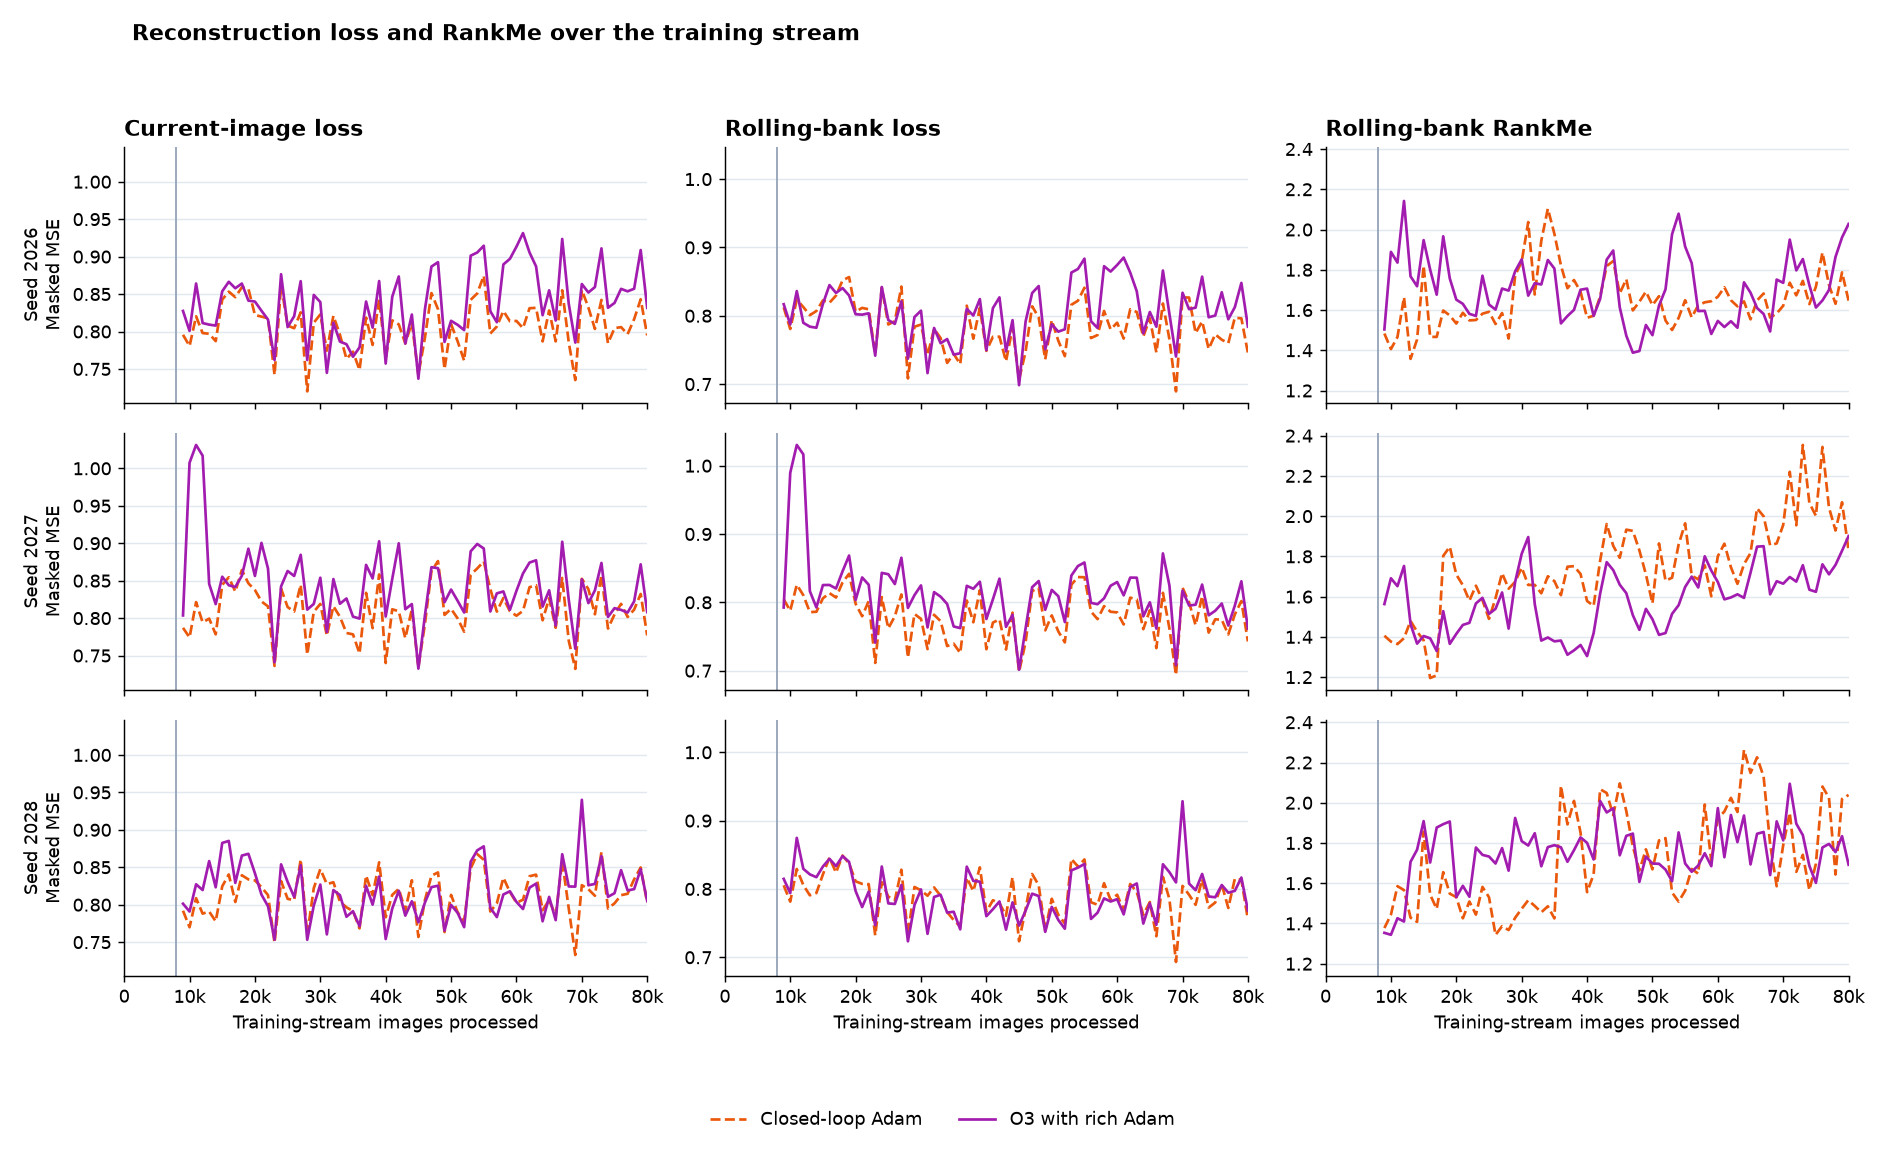

Run the watcher cell at the bottom for live plots while this notebook is open.

## Validation and held-out outcomes

| Split | Seed | Controller | Reconstruction MSE | RankMe | Feature variance |
| --- | --- | --- | --- | --- | --- |
 | Validation | 2026 | Plain Adam | 0.95105 | 2.37592 | 0.102381 | 
 | Validation | 2026 | Rich Adam | 0.936467 | 3.5746 | 0.396333 | 
 | Validation | 2027 | Plain Adam | 0.930102 | 3.29432 | 0.250984 | 
 | Validation | 2027 | Rich Adam | 0.962654 | 3.15251 | 0.153587 | 
 | Validation | 2028 | Plain Adam | 0.933942 | 3.90149 | 0.250375 | 
 | Validation | 2028 | Rich Adam | 0.906263 | 3.01229 | 0.379351 | 
 | Test | 2026 | Plain Adam | 0.947067 | 2.37016 | 0.0974706 | 
 | Test | 2026 | Rich Adam | 0.928512 | 3.59258 | 0.384889 | 
 | Test | 2027 | Plain Adam | 0.915984 | 3.28712 | 0.260122 | 
 | Test | 2027 | Rich Adam | 0.957868 | 3.19549 | 0.146583 | 
 | Test | 2028 | Plain Adam | 0.92064 | 4.04901 | 0.256959 | 
 | Test | 2028 | Rich Adam | 0.895841 | 3.00475 | 0.375793 | 

## Matched prediction errors

Rows with a nonzero training action. Early and late are the first and last quarter.

| Seed | Predictor | Window | Train transitions | current_loss | bank_loss | rankme | variance | Composite RMSE | O3 score RMSE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | 2026 | plain Adam | all | 48000 | 0.0040881 | 0.0014182 | 0.0075507 | 0.0015192 | 2.00556 | 0.02625 | 
 | 2026 | plain Adam | early | 12000 | 0.0039425 | 0.0017138 | 0.0071035 | 0.0011769 | 1.75480 | 0.02487 | 
 | 2026 | plain Adam | late | 12000 | 0.0031697 | 0.00092353 | 0.0059651 | 0.001802 | 1.97593 | 0.02046 | 
 | 2026 | rich Adam | all | 48000 | 0.0041324 | 0.001386 | 0.0074938 | 0.0014499 | 1.95728 | 0.02675 | 
 | 2026 | rich Adam | early | 12000 | 0.003998 | 0.0016698 | 0.0071419 | 0.0010848 | 1.71357 | 0.02587 | 
 | 2026 | rich Adam | late | 12000 | 0.0031594 | 0.00088666 | 0.0052799 | 0.0017967 | 1.89885 | 0.02005 | 
 | 2027 | plain Adam | all | 48000 | 0.0041208 | 0.0013003 | 0.0066481 | 0.0016799 | 4.79695 | 0.02616 | 
 | 2027 | plain Adam | early | 12000 | 0.0042889 | 0.0016853 | 0.00758 | 0.0020381 | 5.76668 | 0.02724 | 
 | 2027 | plain Adam | late | 12000 | 0.0031721 | 0.0013652 | 0.0067266 | 0.0012408 | 3.77075 | 0.02046 | 
 | 2027 | rich Adam | all | 48000 | 0.0042317 | 0.0012833 | 0.0061133 | 0.0015651 | 4.46308 | 0.02659 | 
 | 2027 | rich Adam | early | 12000 | 0.0043019 | 0.0015235 | 0.0071068 | 0.0019215 | 5.43328 | 0.02734 | 
 | 2027 | rich Adam | late | 12000 | 0.0033076 | 0.0012707 | 0.0063097 | 0.0011781 | 3.57099 | 0.02102 | 
 | 2028 | plain Adam | all | 48000 | 0.0034456 | 0.00118 | 0.006436 | 0.0013553 | 1.84187 | 0.02255 | 
 | 2028 | plain Adam | early | 12000 | 0.0041349 | 0.0015625 | 0.010073 | 0.0017902 | 2.52992 | 0.02744 | 
 | 2028 | plain Adam | late | 12000 | 0.003071 | 0.0010403 | 0.0061705 | 0.0011108 | 1.57013 | 0.02021 | 
 | 2028 | rich Adam | all | 48000 | 0.0032586 | 0.0012024 | 0.0085123 | 0.0012693 | 1.89748 | 0.02209 | 
 | 2028 | rich Adam | early | 12000 | 0.0038414 | 0.00159 | 0.015062 | 0.0015614 | 2.73077 | 0.02805 | 
 | 2028 | rich Adam | late | 12000 | 0.0028548 | 0.0010712 | 0.0065144 | 0.001325 | 1.80848 | 0.01890 | 

## Immediate action ranking

Both predictors see the same audited states. The audit executes all three actions from identical copies and measures regret as the selected action’s O3 score minus the best observed score.

| Seed | Predictor | Paired states | Optimal action rate | Mean O3 regret |
| --- | --- | --- | --- | --- |
 | 2026 | plain Adam | 281 | 96.44% | 0.000469032 | 
 | 2026 | rich Adam | 281 | 58.72% | 0.00868712 | 
 | 2027 | plain Adam | 281 | 88.97% | 0.00104478 | 
 | 2027 | rich Adam | 281 | 78.29% | 0.00494638 | 
 | 2028 | plain Adam | 281 | 94.66% | 0.000767287 | 
 | 2028 | rich Adam | 281 | 56.58% | 0.00914737 | 

In [ ]:
# Run this cell to watch the training curves. Interrupt it to stop watching.
from IPython.display import Image, clear_output, display
from pathlib import Path
import json, time

chart_path = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\rich-predictor\\training-curves.png')
status_path = chart_path.with_name('status.json')
while True:
    try:
        status = json.loads(status_path.read_text(encoding='utf-8'))
        png = chart_path.read_bytes()
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    display(Image(data=png))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)
